# 23 — El catálogo de variables y su validación en varios años

## Para qué es este cuaderno

Los cuadernos 17 a 21 revisaron, probaron y validaron variables y fuentes nuevas. El propietario pidió dos cosas:
- **un resumen de todas las variables que quedan, y por qué**;
- **validarlas en diferentes tiempos y contextos de la historia**, no solo en 2026, con probabilidades
  razonables: «no es Dios»; 60-70 % es creíble, 80-90 % no.

**Partes del cuaderno:**
1. El **catálogo**: cada variable, su fuente, si se conoce al predecir, su evidencia y la decisión.
2. **Qué contextos ve el modelo** en su entrenamiento: El Niño, La Niña, crisis de la red, COVID…
3. **Por qué no se mezclan días al azar** entre entrenamiento y prueba: se demuestra con datos.
4. **Lo que dice la investigación** sobre cómo entrenar y validar bien este tipo de pronóstico.
5. **Un error de método** del motor que la validación en varios años sacó a la luz, y su corrección.
6. **La validación de cada capa en cuatro años** (2023, 2024, 2025, 2026), cada uno entrenado solo con lo
   anterior (fila `validacion_por_capas_multianual`, fijada antes de calcular).
7. **Las técnicas de entrenamiento** que propone la literatura, probadas una por una (fila
   `tecnicas_de_entrenamiento`).
8. **Qué tan seguras son las probabilidades** que emite el modelo, y si se cumplen.
9. **La corrección del motor** en el reentrenamiento semanal.
10. **Entrenar con fechas escogidas**, de forma marcada y controlada (pedido del propietario).
11. **El contexto con compuerta**: cada factor solo cuando su gatillo está activo.
12. **La confirmación** con el protocolo completo.
13. **La respuesta semanal**: media, rango y probabilidad por día, guardada para verificarla.

In [1]:
import sys, pathlib, warnings
RAIZ = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "CLAUDE.md").exists())
sys.path.insert(0, str(RAIZ / "notebooks")); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, lightgbm as lgb
from matplotlib import pyplot as plt
import pronostico as pr, indices as ix
AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE, VIOLETA, ROJO = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948")
TINTA, TINTA2, MUDO, SUP = "#0b0b0b", "#52514e", "#898781", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SUP, "axes.facecolor": SUP, "axes.spines.top": False,
    "axes.spines.right": False, "axes.edgecolor": MUDO, "axes.grid": True, "grid.color": "#e6e5e1",
    "grid.linewidth": .6, "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": TINTA, "font.size": 10,
    "legend.frameon": False})

---
# 1. El catálogo: las variables que quedan y por qué

In [2]:
CAT = pd.DataFrame([
 # capa, variable, que mide, fuente, al predecir, desde, evidencia, decision
 ["Calendario", "día de la semana, festivo, puente, víspera, día después, quincena, vacaciones, Semana Santa, Navidad, fin de año, regreso a clases", "el ritmo social", "calendario de Colombia", "por adelantado", "2020", "72 % de la variación diaria (cuaderno 14)", "ENTRA: es el control"],
 ["Calendario", "COVID fuerte y parcial, paro nacional 2021", "episodios únicos", "fechas fijas", "por adelantado", "2020", "hunden la notificación de todo (cuaderno 20)", "ENTRA como marca, no como predictor"],
 ["Estación", "3 armónicos del año", "la época del año", "la fecha", "por adelantado", "—", "mayo concentra picos (cuaderno 14)", "ENTRA"],
 ["Nivel", "media de 28 días", "el nivel de la red", "triage del hospital", "hasta ayer", "2020", "sigue los escalones (cuaderno 15)", "ENTRA"],
 ["Memoria", "desvío de la última semana, del último día y del mismo día de la semana pasada", "la inercia de corto plazo", "triage del hospital", "hasta ayer", "2020", "autocorrelación de +0,26 a 1 día (cuaderno 14)", "ENTRA"],
 ["Clima", "4 índices de estado (soleado y seco frente a nublado y húmedo; cálido; viento; sol con humedad)", "cómo está el tiempo", "ERA5 + NASA POWER", "hasta ayer (observado)", "2010", "IRA de la ciudad +6-7 %; triage +1-2 % (cuaderno 17)", "ENTRA"],
 ["Clima", "3 índices de cambio brusco", "si el tiempo cambió de golpe", "ERA5 + NASA POWER", "hasta ayer", "2010", "81 % de los cambios (cuaderno 17)", "ENTRA"],
 ["Clima", "racha seca; días desde la última semana muy lluviosa", "sequía y lluvia reciente", "NASA POWER", "hasta ayer", "2010", "mayores +4,6 % tras lluvia; adultos +2,8 % tras racha seca (cuaderno 21)", "ENTRA"],
 ["Clima", "lluvia del ERA5", "—", "Open-Meteo Archive", "—", "—", "10 veces lo real, correlación −0,02 (cuaderno 17)", "FUERA: está rota"],
 ["Salud pública", "familia respiratoria (IRA total, 0-4, 60+)", "la ola respiratoria de la ciudad", "SIVIGILA + Power BI", "semana anterior", "2012", "mueve el respiratorio del hospital +10-14 % (cuaderno 13)", "ENTRA"],
 ["Salud pública", "violencias y agresiones; salud mental e intoxicaciones; materno-perinatal; inmunoprevenibles", "las otras urgencias de la ciudad", "SIVIGILA + Power BI", "semana anterior", "2015", "familias casi independientes, r ≤ 0,19 (cuaderno 19)", "ENTRA"],
 ["Salud pública", "familia digestiva (EDA)", "diarrea de la ciudad", "solo microdatos", "NO: ~8 meses tarde", "2012", "+15,7 % con sequía (cuaderno 19)", "FUERA hasta tener fuente a tiempo"],
 ["Salud pública", "IRAG hospitalizada", "gravedad respiratoria", "microdatos / rutinaria", "no empalma en 2026", "2012", "—", "FUERA"],
 ["Red de salud", "peso de Nueva EPS y de SURA (28 días)", "el estado de la red", "triage por asegurador", "hasta ayer", "2020", "dos aseguradoras son el 80-90 % (cuaderno 18)", "ENTRA"],
 ["Red de salud", "cambio de 28 días de Nueva EPS y del resto; Herfindahl", "si la red se mueve", "triage por asegurador", "hasta ayer", "2020", "la caída de Nueva EPS es de acceso (cuaderno 18)", "ENTRA"],
 ["Red de salud", "resolución de la Supersalud sobre Nueva EPS (30 días)", "intervenciones y cambios", "Supersalud (capturado)", "fecha pública", "2024", "coincide con el escalón de noviembre de 2025 (cuaderno 18)", "ENTRA"],
 ["Red de salud", "afiliados por EPS en Manizales; uso por afiliado", "tamaño y acceso de cada EPS", "MinSalud (capturado)", "1 mes", "2025-07", "−20 % afiliados y −60 % triage en Nueva EPS (cuaderno 18)", "PENDIENTE: 14 meses de historia"],
 ["Red de salud", "quejas por EPS (PQRD), giros de ADRES", "barreras y pagos", "Supersalud, ADRES", "1-2 meses", "2017 / 2020", "—", "PENDIENTE: sin captura automática"],
 ["Regímenes", "ONI, El Niño, La Niña", "el clima de fondo del año", "NOAA (capturado)", "2 meses de retraso", "1950", "La Niña sube violencias y salud mental; El Niño +3,6 % (cuaderno 20)", "ENTRA; El Niño se prueba prospectivamente"],
 ["Regímenes", "sismo fuerte (7 días)", "sismos M ≥ 4,5 a menos de 150 km", "USGS", "minutos", "2010", "sin efecto, con 40 episodios (cuaderno 20)", "ENTRA (pesa poco)"],
 ["Eventos", "Feria, eventos de Manizales, fiestas de Caldas, días especiales", "aglomeraciones", "calendarios propios", "por adelantado", "2020", "0,5 % de la ganancia (cuaderno 15)", "FUERA del total; la Feria ya se refleja en el calendario"],
 ["Motivo", "motivo de consulta limpio (NLP)", "el desenlace específico", "NLP/", "—", "2025", "es desenlace, no predictor (CLAUDE.md)", "PENDIENTE: corpus sin procesar"],
], columns=["capa", "variable", "qué mide", "fuente", "¿se sabe al predecir?", "desde", "evidencia", "decisión"])
pd.set_option("display.max_colwidth", 120)
CAT

,capa,variable,qué mide,fuente,¿se sabe al predecir?,desde,evidencia,decisión
0,Calendario,"día de la semana, festivo, puente, víspera, día después, quincena, vacaciones, Semana Santa, Navidad, fin de año, re...",el ritmo social,calendario de Colombia,por adelantado,2020,72 % de la variación diaria (cuaderno 14),ENTRA: es el control
1,Calendario,"COVID fuerte y parcial, paro nacional 2021",episodios únicos,fechas fijas,por adelantado,2020,hunden la notificación de todo (cuaderno 20),"ENTRA como marca, no como predictor"
2,Estación,3 armónicos del año,la época del año,la fecha,por adelantado,—,mayo concentra picos (cuaderno 14),ENTRA
3,Nivel,media de 28 días,el nivel de la red,triage del hospital,hasta ayer,2020,sigue los escalones (cuaderno 15),ENTRA
4,Memoria,"desvío de la última semana, del último día y del mismo día de la semana pasada",la inercia de corto plazo,triage del hospital,hasta ayer,2020,"autocorrelación de +0,26 a 1 día (cuaderno 14)",ENTRA
5,Clima,4 índices de estado (soleado y seco frente a nublado y húmedo; cálido; viento; sol con humedad),cómo está el tiempo,ERA5 + NASA POWER,hasta ayer (observado),2010,IRA de la ciudad +6-7 %; triage +1-2 % (cuaderno 17),ENTRA
6,Clima,3 índices de cambio brusco,si el tiempo cambió de golpe,ERA5 + NASA POWER,hasta ayer,2010,81 % de los cambios (cuaderno 17),ENTRA
7,Clima,racha seca; días desde la última semana muy lluviosa,sequía y lluvia reciente,NASA POWER,hasta ayer,2010,"mayores +4,6 % tras lluvia; adultos +2,8 % tras racha seca (cuaderno 21)",ENTRA
8,Clima,lluvia del ERA5,—,Open-Meteo Archive,—,—,"10 veces lo real, correlación −0,02 (cuaderno 17)",FUERA: está rota
9,Salud pública,"familia respiratoria (IRA total, 0-4, 60+)",la ola respiratoria de la ciudad,SIVIGILA + Power BI,semana anterior,2012,mueve el respiratorio del hospital +10-14 % (cuaderno 13),ENTRA


**Lectura.** De 22 grupos de variables revisados en los cuadernos 13 a 21:
- **15 entran**: el calendario y las marcas de episodios únicos, la estación, el nivel, la memoria, 9 índices de clima, 5 familias de salud pública, 6 variables de red y los regímenes;
- **4 quedan fuera**:
  - la lluvia del ERA5, porque está rota;
  - la familia digestiva y la IRAG hospitalizada, porque no existen el día en que se predice;
  - los eventos en el total, porque el calendario ya los recoge;
- **3 están pendientes de historia o de captura**: afiliados por EPS, quejas y giros, y el motivo de consulta.

El criterio para entrar no fue «tiene efecto». Fue **«se conoce el día de la predicción, tiene historia suficiente y no se construyó mirando 2026»**. Si además *aporta al pronóstico del total*, eso no lo dice esta tabla: lo dicen las secciones 6, 7, 10 y 11, en cuatro años distintos.

---
# 2. Qué contextos ve el modelo cuando aprende

Para cada año de prueba: cuántos días de cada contexto tenía el entrenamiento (todo lo anterior, desde 2020) y
cuántos trae el año que se predice.

In [3]:
pr.usar("h"); y, cal = pr.cargar()
PAS = ix.contexto_holistico(cal.index).reindex(y.index)
R = ix.regimenes_diarios().reindex(y.index)
ctx = pd.DataFrame({"El Niño": R.el_nino, "La Niña": R.la_nina, "COVID": R.covid_fuerte + R.covid_parcial, "crisis de la red": R.crisis_red,
                    "ola respiratoria (> +1 desv.)": (PAS.ext_h_fam_respiratoria > 1).astype(float), "racha seca > 14 días": (PAS.ext_h_racha_seca > 14).astype(float),
                    "temporada de Navidad": cal.reindex(y.index).es_temporada_navidad, "vacaciones escolares": cal.reindex(y.index).es_vacaciones_escolares})
filas = []
for a in [2023, 2024, 2025, 2026]:
    tr, te = ctx.loc[:f"{a - 1}-12-31"], ctx.loc[f"{a}-01-01":f"{a}-12-31"]
    filas.append(pd.Series({**{f"{c} · entrena": int(tr[c].sum()) for c in ctx}, **{f"{c} · prueba": int(te[c].sum()) for c in ctx}}, name=a))
cob = pd.DataFrame(filas)
cob.T.rename(columns=str)

,2023,2024,2025,2026
El Niño · entrena,152,305,487,487
La Niña · entrena,668,758,758,789
COVID · entrena,716,716,716,716
crisis de la red · entrena,32,32,139,170
ola respiratoria (> +1 desv.) · entrena,147,147,189,189
racha seca > 14 días · entrena,73,74,83,83
temporada de Navidad · entrena,111,148,185,222
vacaciones escolares · entrena,366,488,610,732
El Niño · prueba,153,182,0,82
La Niña · prueba,90,0,31,59


**Lectura.** Hasta 2025 el entrenamiento vio casi todos los contextos:
- 487 días de El Niño;
- 789 de La Niña;
- 716 de COVID, marcados;
- más de 600 de vacaciones;
- 4 a 6 temporadas de Navidad.

Hay dos huecos que importan:
1. **La crisis de la red es nueva.** Antes de 2025 el modelo solo conocía 32 días de crisis. En 2026 tiene que predecir 263, contra 170 vistos en todo el entrenamiento. Ningún orden de los datos arregla eso: es un contexto que **todavía no ha pasado lo suficiente**.
2. **No hubo ola respiratoria fuerte (> +1 desviación) en 2025 ni en 2026**, así que esa capa no se pudo poner a prueba en esos años. Solo 2024 trae 42 días.

Esto es lo que el propietario buscaba con «suficientes datos de cada contexto». La respuesta honesta es que la cantidad la pone la historia, no el muestreo. Con 4 episodios ENSO y una crisis de la red, hay contextos de los que **solo se puede aprender lo que ya ocurrió**.

---
# 3. Por qué no se mezclan días al azar

La propuesta del propietario era «datos escogidos y aleatorios». Se prueban las dos formas con el mismo modelo
(LightGBM, mediana a 1 día) y dos juegos de entradas (la base, y la base con todo el contexto H):
- **aleatoria:** el 80 % de los días hasta el año de prueba para entrenar y el 20 % restante, mezclado, para probar;
- **temporal:** entrenar con todo lo anterior y probar el año entero, como pasaría en la realidad.

Se hace hasta 2025 y hasta 2026, y con los dos objetivos del árbol (el conteo, y el desvío frente al nivel: ver
sección 5). «Acierta» es acertar si el día queda por encima o por debajo de lo que espera el calendario.

In [4]:
import anual
D = anual.preparar(); X, ly = D["X"], D["ly"]
def prueba(cols, ia, ib, rel):
    off_a = X.nivel.values[ia] if rel else 0; off_b = X.nivel.values[ib] if rel else 0
    C = [c for c in cols if not (rel and c == "nivel")]
    m = lgb.LGBMRegressor(objective="l1", **pr.LightGBM.PARAM).fit(X[C].values[ia], ly.values[ia] - off_a)
    p = np.exp(m.predict(X[C].values[ib]) + off_b); r = np.exp(ly.values[ib])
    Z = lambda i: np.c_[np.ones(len(i)), X[anual.CTRL(X)].values[i]]
    b, *_ = np.linalg.lstsq(Z(ia), ly.values[ia], rcond=None); esp = np.exp(Z(ib) @ b)
    return 100 * np.mean(np.abs(p - r) / r), 100 * np.mean((p > esp) == (r > esp))
fil = []
for fin in ["2025", "2026"]:
    n_ini = X.index.get_loc(X.loc[f"{fin}-01-01":].index[0]); n_fin = len(X.loc[:f"{fin}-12-31"])
    idx = np.random.default_rng(0).permutation(n_fin); k = int(.8 * n_fin)
    parts = {"aleatoria 80/20": (np.sort(idx[:k]), np.sort(idx[k:])), "temporal (la real)": (np.arange(n_ini), np.arange(n_ini, n_fin))}
    for juego in ["base", "base + todo H"]:
        cols = [c for c in X.columns if D["capa"][c] in anual.JUEGOS[juego]]
        for nom, (ia, ib) in parts.items():
            for rel in [False, True]:
                mp, ac = prueba(cols, ia, ib, rel)
                fil.append({"prueba hasta": fin, "objetivo del árbol": "desvío del nivel" if rel else "conteo", "partición": nom, "juego": juego, "MAPE %": mp, "acierta %": ac})
pd.DataFrame(fil).pivot_table(index=["prueba hasta", "objetivo del árbol", "partición"], columns="juego", values=["acierta %", "MAPE %"]).round(1)

MAPE %                \
juego                                                base base + todo H   
prueba hasta objetivo del árbol partición                                 
2025         conteo             aleatoria 80/20       9.0           9.5   
                                temporal (la real)    9.1           9.6   
             desvío del nivel   aleatoria 80/20       9.1           9.3   
                                temporal (la real)    8.5           8.6   
2026         conteo             aleatoria 80/20       9.1           9.2   
                                temporal (la real)    9.2          13.7   
             desvío del nivel   aleatoria 80/20       9.2           9.2   
                                temporal (la real)    9.0           9.3   

                                                   acierta %                
juego                                                   base base + todo H  
prueba hasta objetivo del árbol partición                                   
2025         conteo             aleatoria 80/20         66.3          64.2  
                                temporal (la real)      57.0          56.2  
             desvío del nivel   aleatoria 80/20         66.3          63.5  
                                temporal (la real)      59.5          58.6  
2026         conteo             aleatoria 80/20         64.7          63.5  
                                temporal (la real)      66.5          52.1  
             desvío del nivel   aleatoria 80/20         66.0          67.0  
                                temporal (la real)      66.2          61.2

**Lectura.** **Mezclar días al azar infla el resultado, y además engaña sobre qué variables sirven.**
- **Hasta 2025:** la partición aleatoria da 66 % de acierto; la temporal, la que pasaría en la realidad, da entre 57 y 60 %. Son **7 a 9 puntos de mentira**.
- **Hasta 2026, árbol sobre el conteo y con contexto H:** con días al azar el modelo parece bueno (63,5 % de acierto, error del 9,2 %). Hacia adelante cae a **52 % y 13,7 %**. La mezcla esconde por completo el fallo de extrapolación de la sección 5.
- **Lo más grave, en 2026 con el método corregido:** con días al azar el contexto H **parece ayudar** (67,0 % contra 66,0 % de la base). Hacia adelante **perjudica** (61,2 % contra 66,2 %). Una mezcla al azar habría hecho meter variables que empeoran el pronóstico real.

La razón la explican Bergmeir, Hyndman y Koo (2018): la mezcla solo es válida si el residuo no tiene memoria, la serie es estable y no hay variables externas. Aquí falla en las tres. Un índice de la red o del clima «delata» la época del año y el modelo copia a los vecinos del futuro. Por eso, en este proyecto, lo «aleatorio» solo es legítimo **dentro** del entrenamiento: el remuestreo de bloques, que se prueba en la sección 7.

---
# 4. Lo que dice la investigación: cómo entrenar bien este tipo de pronóstico

El propietario pidió basar el entrenamiento en investigación, no en intuición. Se revisó la literatura de dos
frentes: **cómo validar y muestrear series de tiempo sin filtrar el futuro**, y **cómo se pronostican las urgencias
con variables externas y cómo se calibran sus probabilidades**. Lo que sigue es lo que se aplica aquí; las
referencias completas están en `docs/CONTEXTO.md` (entrada del 2026-10-05).

| Técnica | Qué es, en simple | Fuente | ¿Se aplica aquí? |
|---|---|---|---|
| **Origen rodante / año a ciegas** | Entrenar con el pasado y predecir hacia adelante; nunca al revés | Tashman 2000; Cerqueira, Torgo y Mozetič 2020 | **Sí, es la prueba final.** Con series que cambian de nivel, es la única estimación honesta |
| Partición aleatoria (k-fold) | Mezclar días de entrenamiento y prueba | Bergmeir, Hyndman y Koo 2018 | **No.** Solo vale si el residuo no tiene memoria, la serie es estable y no hay variables externas; aquí falla en las tres (memoria +0,42) |
| k-fold por bloques con purga y embargo | Bloques de meses, con 35 días de colchón alrededor de la prueba | López de Prado 2018; Racine 2000 | Solo para **afinar** dentro del entrenamiento, nunca para reportar |
| **Objetivo relativo al nivel** | Que el árbol aprenda «cuánto se aparta del nivel» y no el conteo | Hewamalage, Ackermann y Bergmeir 2023 | **Sí: corrige un error del motor** (sección 5) |
| Peso bajo al periodo COVID | Que la interrupción no enseñe una forma anual falsa | Hyndman y Rostami-Tabar 2025 | Se prueba (T1) |
| Peso a lo reciente | Con rupturas, el pasado lejano vale menos | Pesaran, Pick y Pranovich 2013 | Se prueba (T2) |
| **Peso a contextos raros** | El equivalente legítimo de «datos escogidos»: los días raros pesan más, sin mirar el futuro | Sugiyama, Krauledat y Müller 2007 (ponderación) | Se prueba (T3) |
| **Remuestreo por bloques (bagging)** | El «aleatorio» legítimo: se rehace el entrenamiento con bloques de 28 días al azar y se promedia | Bergmeir, Hyndman y Benítez 2016 | Se prueba (T4) |
| Calibración de Platt | Corrige probabilidades exageradas con el año anterior | Niculescu-Mizil y Caruana 2005; Kull et al. 2017 | Se prueba; la isotónica no, con pocos días sobreajusta |
| Combinar por promedio de cuantiles | El promedio simple es difícil de batir | Wang, Hyndman et al. 2023; Lichtendahl et al. 2013 | **Ya en uso** (cuaderno 22) |
| Modelo global por bandas o aseguradores | Un solo modelo para todas las series, con más ejemplos de lo raro | Montero-Manso y Hyndman 2021 | Pendiente: siguiente paso |
| Diebold-Mariano, Giacomini-White, conjunto de confianza de modelos | Decidir si una diferencia es real | Diebold y Mariano 1995; Giacomini y White 2006; Hansen, Lunde y Nason 2011 | Remuestreo por bloques ya en uso; Giacomini-White pendiente |

**Lo que dice la literatura de urgencias, que hay que tener presente al leer los resultados:**
- El calendario explica entre 31 y 75 % de la variación y deja errores de 4 a 14 % (Wargon et al. 2009, 9 estudios).
  Nuestro 72 % y 10 % están en ese rango: **el control no es débil**.
- **Añadir el clima casi nunca mejora el error del total**: São Paulo (Marcilio et al. 2013: 10,8 % sin temperatura,
  11,5 % con ella), Porto Alegre (Calegari et al. 2016), Londres (Vollmer et al. 2021), Tampere (Tuominen et al.
  2022). El clima se ve en la serie respiratoria y en grupos de edad, no en el total.
- Lo que **sí** ayuda de forma consistente es el **estado del sistema**: avisos de ambulancia (−6 puntos de error,
  Asheim et al. 2019), camas de la red (Tuominen et al. 2022), epidemia de influenza (Murtas et al. 2022).
- Solo 5 de 30 estudios dan intervalos de predicción (Petravić et al. 2025). Dar distribuciones, como aquí, ya es
  más de lo habitual.

---
# 5. Un error de método que destapó la validación en varios años

La primera corrida de la validación anual (la regla preregistrada, tal cual) dio una base con **BSS de −105 % en
2024** y una cobertura del 80 % de solo 33 %. La causa: el LightGBM del motor aprende el **conteo** (su
logaritmo) y recibe el nivel como una entrada más. **Un árbol no puede predecir un valor que nunca vio**: cuando el
nivel de 2024 superó todo lo anterior (226 triages por día), el modelo se quedó pegado al techo de 2023. Con el
reentrenamiento semanal de los cuadernos 15-22 el problema casi no se nota, porque el árbol se pone al día cada
semana; congelado un año, aparece entero.

La corrección (T0) es que el árbol aprenda **el desvío frente al nivel**, log(y) − nivel, y que el nivel se sume
después. Se registró como desviación antes de seguir (fila `tecnicas_de_entrenamiento`).

In [5]:
import anual
P = pd.concat([pd.read_parquet(RAIZ / "salidas/pronostico/anual_tecnicas.parquet"), pd.read_parquet(RAIZ / "salidas/pronostico/anual_capas.parquet")])
M = anual.metricas(P[P["año"] >= 2023])
ver = ["acierta sube/baja %", "BSS sube %", "cob80 %", "MAPE %"]
M.loc[(["original", "T0"], ["base", "base + todo H"]), ver].unstack("año").round(1)

acierta sube/baja %                   BSS sube %  \
año                                   2023  2024  2025  2026       2023   
tecnica  juego                                                            
original base                         59.2  42.4  59.7  66.9       -7.6   
         base + todo H                55.6  39.0  57.0  52.1      -17.7   
T0       base                         57.0  66.3  59.5  66.2       -9.3   
         base + todo H                58.1  64.0  58.6  61.2      -14.1   

                                         cob80 %                   MAPE %  \
año                      2024 2025  2026    2023  2024  2025  2026   2023   
tecnica  juego                                                              
original base          -105.0 -2.1  12.5    69.3  32.6  66.0  74.1    8.6   
         base + todo H -113.9 -7.1 -11.8    71.0  34.6  65.2  81.0    9.5   
T0       base             4.1  2.4  11.4    73.2  73.3  75.1  74.5    9.1   
         base + todo H   -1.2  1.3   8.5    68.8  70.2  72.3  76.4    9.0   

                                         
año                     2024 2025  2026  
tecnica  juego                           
original base           14.5  8.9   9.2  
         base + todo H  17.6  9.6  13.5  
T0       base            8.8  8.5   9.0  
         base + todo H   9.3  8.6   9.3

**Lectura.** La corrección cambia 2024 de raíz con la base:

| 2024, base | Árbol sobre el conteo | Árbol sobre el desvío |
|---|---|---|
| BSS de «sube» | −105 % | **+4,1 %** |
| Acierto | 42 % | **66 %** |
| Cobertura del 80 % | 33 % | **73 %** |
| MAPE | 14,5 % | **8,8 %** |

Con todo el contexto H en 2026, el árbol sobre el conteo da un BSS de pico de **−70 %**: el peso de Nueva EPS se hundió por debajo de todo lo visto. Con el desvío, +6 %. En 2023 y 2026, la base sobre el conteo queda apenas por encima (−7,6 frente a −9,3; +12,5 frente a +11,4), así que la corrección **no regala aciertos**: quita el riesgo de catástrofe cuando el nivel sale de lo conocido.

**Lo que queda pendiente:** `pronostico.py`, el motor de los cuadernos 15 a 22, tiene el mismo defecto. Con reentrenamiento semanal se nota mucho menos, pero existe. Corregirlo es el siguiente experimento y va con su propia fila preregistrada.

---
# 6. La validación de cada capa en cuatro años (con el método corregido)

Para cada año de prueba se entrena con todo lo anterior. **Una capa «aporta» si mejora la probabilidad de «sube»
frente a la base en al menos 3 de los 4 años** (regla preregistrada).

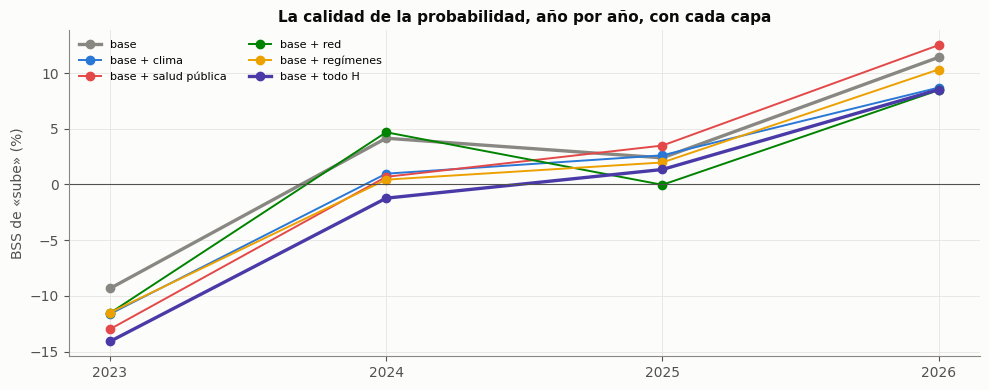

,años en que mejora a la base,mejora media del BSS (puntos),¿aporta? (≥ 3 de 4 años)
juego,,,
base + clima,1,-2.0,no
base + salud pública,2,-1.2,no
base + red,1,-1.8,no
base + regímenes,0,-1.8,no
base + todo H,0,-3.5,no


acierta sube/baja %                   BSS sube %       \
año                                 2023  2024  2025  2026       2023 2024   
juego                                                                        
base                                57.0  66.3  59.5  66.2       -9.3  4.1   
base + clima                        58.4  65.7  56.7  64.3      -11.6  1.0   
base + salud pública                55.3  65.4  60.0  63.1      -13.0  0.7   
base + red                          57.8  67.1  57.8  64.6      -11.5  4.7   
base + regímenes                    56.7  65.2  60.5  67.3      -11.5  0.4   
base + todo H                       58.1  64.0  58.6  61.2      -14.1 -1.2   

                                BSS pico %                cob80 %              \
año                  2025  2026       2023 2024 2025 2026    2023  2024  2025   
juego                                                                           
base                  2.4  11.4      -24.0  9.1  5.3  7.0    73.2  73.3  75.1   
base + clima          2.6   8.7      -32.1  8.1  7.1  6.9    72.3  75.3  74.2   
base + salud pública  3.5  12.5      -22.9  8.4  8.6  7.2    69.6  71.9  76.2   
base + red           -0.0   8.5      -17.7  7.7  5.2  1.6    67.4  74.7  72.3   
base + regímenes      2.0  10.3      -30.1  8.9  5.3  6.5    71.0  72.5  74.0   
base + todo H         1.3   8.5      -24.8  4.5  5.9  6.0    68.8  70.2  72.3   

                           MAPE %                 
año                   2026   2023 2024 2025 2026  
juego                                             
base                  74.5    9.1  8.8  8.5  9.0  
base + clima          74.5    9.2  9.1  8.5  9.0  
base + salud pública  74.5    9.1  9.1  8.5  8.9  
base + red            79.5    9.0  8.7  8.6  9.2  
base + regímenes      74.1    9.2  9.1  8.6  8.9  
base + todo H         76.4    9.0  9.3  8.6  9.3

In [6]:
B = M.loc["T0", "BSS sube %"].unstack("año").reindex(list(anual.JUEGOS))
mejora = B.sub(B.loc["base"], axis=1)
veredicto = pd.DataFrame({"años en que mejora a la base": (mejora > 0).sum(axis=1), "mejora media del BSS (puntos)": mejora.mean(axis=1).round(1),
                          "¿aporta? (≥ 3 de 4 años)": np.where((mejora > 0).sum(axis=1) >= 3, "SÍ", "no")}).drop("base")
fig, ax = plt.subplots(figsize=(10, 4))
for juego, c in zip(anual.JUEGOS, [MUDO, AZUL, ROJO, VERDE, AMARILLO, VIOLETA]):
    ax.plot(B.columns, B.loc[juego], "-o", color=c, lw=2.4 if juego in ("base", "base + todo H") else 1.4, label=juego)
ax.axhline(0, color=TINTA2, lw=.8); ax.set_xticks(B.columns); ax.set_ylabel("BSS de «sube» (%)"); ax.legend(fontsize=8, ncol=2)
ax.set_title("La calidad de la probabilidad, año por año, con cada capa"); plt.tight_layout(); plt.show()
display(veredicto)
M.loc["T0", ["acierta sube/baja %", "BSS sube %", "BSS pico %", "cob80 %", "MAPE %"]].unstack("año").reindex(list(anual.JUEGOS)).round(1)

**Lectura.** **Con la regla preregistrada, ninguna capa externa aporta al pronóstico del total en 3 de 4 años.**

| Capa | Años que mejora a la base | Cambio medio del BSS |
|---|---|---|
| Salud pública | 2 (2025 y 2026, +1,1 cada uno) | −1,2 |
| Clima | 1 | −2,0 |
| Red | 1 | −1,8 |
| Regímenes | 0 | −1,8 |
| Todo H junto | 0 | −3,5 |

Es lo que encuentra la literatura en hospitales parecidos. Añadir clima no mejoró el error del total en São Paulo (Marcilio et al. 2013), Porto Alegre (Calegari et al. 2016), Londres (Vollmer et al. 2021) ni Tampere (Tuominen et al. 2022).

**Lo que esto NO dice: que el contexto no importe.** Los cuadernos 17 a 21 midieron efectos reales:
- el clima mueve la IRA de la ciudad un 6-7 %;
- la lluvia mueve la banda de 65+ un 4,6 %;
- La Niña mueve las violencias.

Pero en el total esos efectos son de 1 a 3 %, por debajo del ruido diario del 12,6 %. Es el argumento de dilución de `CLAUDE.md`: el contexto se ve en las partes (edad, motivo, aseguradora), no en la suma. Que salud pública mejore 2025 y 2026, los dos años más recientes, es la pista más prometedora. Coincide con la literatura, que encuentra que el **estado del sistema y de la epidemia** ayuda más que el clima.

La base sola (calendario, estación, nivel y memoria) acierta 57, 66, 60 y 66 % en 2023-2026, con BSS de −9, +4, +2 y +11. Su media de **62 %** es la confiabilidad que el propietario esperaba (60-70 %). 2023 queda por debajo del calendario porque se entrenó con 2020-2022, años de COVID.

---
# 7. Las técnicas de entrenamiento de la investigación, una por una

| | Técnica |
|---|---|
| T0 | Objetivo relativo al nivel (el método corregido) |
| T1 | T0 + peso 0,1 a los días COVID |
| T2 | T0 + más peso a lo reciente (vida media de 1,5 años) |
| T3 | T0 + peso doble a los contextos raros (crisis de la red, ola respiratoria, racha seca) |
| T4 | T0 + remuestreo de bloques de 28 días, 10 veces, y promedio |
| T5 | Todo junto |

Regla preregistrada: una técnica se adopta si mejora el BSS de «sube» frente a T0 en al menos 3 de los 4 años con
todo el contexto H, sin sacar la cobertura del 80 % de 70-88 %.

In [7]:
TEC = ["T0", "T1", "T2", "T3", "T4", "T5"]
filas = []
for j in ["base", "base + salud pública", "base + todo H"]:
    b = M.loc[(TEC, j), "BSS sube %"].unstack("año").droplevel(1)
    d = b.sub(b.loc["T0"], axis=1)
    cob = M.loc[(TEC, j), "cob80 %"].groupby(level=0).mean()
    for t in TEC[1:]:
        filas.append({"juego": j, "técnica": t, **{a: round(b.loc[t, a], 1) for a in b.columns}, "años que mejora a T0": int((d.loc[t] > 0).sum()),
                      "mejora media (puntos)": round(d.loc[t].mean(), 1), "cob80 media %": round(cob[t], 1),
                      "¿se adopta?": "SÍ" if (d.loc[t] > 0).sum() >= 3 and 70 <= cob[t] <= 88 else "no"})
TT = pd.DataFrame(filas).set_index(["juego", "técnica"])
display(M.loc[("T0", ["base", "base + salud pública", "base + todo H"]), "BSS sube %"].unstack("año").round(1))
TT

año                           2023  2024  2025  2026
tecnica juego                                       
T0      base                  -9.3   4.1   2.4  11.4
        base + salud pública -13.0   0.7   3.5  12.5
        base + todo H        -14.1  -1.2   1.3   8.5

2023  2024  2025  2026  años que mejora a T0  \
juego                técnica                                                 
base                 T1      -13.8   2.4  -3.3   6.3                     0   
                     T2       -8.3   6.7  -0.9   6.0                     2   
                     T3      -12.0   3.5   4.7  10.6                     1   
                     T4      -11.2   0.4  -0.3   9.1                     0   
                     T5      -14.5  -1.2  -7.6   1.1                     0   
base + salud pública T1      -13.0  -2.2  -3.2   6.1                     1   
                     T2      -11.7  -0.0  -1.8   5.9                     1   
                     T3      -14.0   0.4   4.9  12.1                     1   
                     T4      -13.2  -2.0  -0.8   8.7                     0   
                     T5      -15.3  -5.2  -8.2   0.5                     0   
base + todo H        T1      -16.8  -3.0  -4.5   2.4                     0   
                     T2      -13.4  -2.1  -4.0   1.8                     1   
                     T3      -10.4  -1.3   1.8   6.3                     2   
                     T4      -14.5  -5.2  -2.8   5.2                     0   
                     T5      -19.3  -7.0  -9.3  -5.4                     0   

                              mejora media (puntos)  cob80 media % ¿se adopta?  
juego                técnica                                                    
base                 T1                        -4.2           69.2          no  
                     T2                        -1.3           72.0          no  
                     T3                        -0.4           75.1          no  
                     T4                        -2.7           73.0          no  
                     T5                        -7.7           68.4          no  
base + salud pública T1                        -4.0           70.4          no  
                     T2                        -2.8           72.2          no  
                     T3                        -0.1           74.7          no  
                     T4                        -2.7           71.7          no  
                     T5                        -8.0           69.2          no  
base + todo H        T1                        -4.1           73.8          no  
                     T2                        -3.0           72.4          no  
                     T3                         0.5           74.5          no  
                     T4                        -2.9           73.6          no  
                     T5                        -8.9           69.8          no

**Lectura.** **Ninguna técnica cumple la regla para adoptarse. Lo más simple (T0) es lo mejor.**
- **T1, peso bajo al COVID:** empeora en los 4 años (−2 a −6 puntos). Con la COVID ya marcada como variable, el modelo aprende de esos días sin copiar su forma, y quitarles peso solo le quita datos.
- **T2, más peso a lo reciente:** empeora en 3 de 4 años. Con solo seis años de historia, descontar el pasado deja demasiado poco.
- **T3, peso doble a contextos raros:** es la menos mala. Mejora 2 de 4 años con H (2023 +3,7 y 2025 +0,5) y acerca la cobertura del 80 % a lo honesto (72-78 % frente a 69-76 %). No llega a la regla, pero es la que se volvería a probar con más historia.
- **T4, remuestreo de bloques:** empeora en 4 de 4. Bergmeir et al. (2016) lo prueban con suavizado exponencial, que sí se beneficia; un LightGBM ya promedia árboles y se vuelve menos nítido.
- **T5, todo junto:** es la peor (−5 a −14 puntos). Los defectos se suman.

Encaja con dos hallazgos de la literatura:
- con pocos datos, cada pieza que se estima mete varianza (Wang, Hyndman et al. 2023, sobre combinaciones);
- elegir entre muchas variantes cuesta del 1 al 2 % aunque se haga bien (Cerqueira, Torgo y Soares 2023).

El equivalente legítimo de los «datos escogidos y aleatorios» **se probó y no mejora**. Queda descartado con evidencia, no por supuesto.

---
# 8. ¿Qué tan seguras son las probabilidades, y se cumplen?

El propietario lo dijo claro: un modelo que asegura 80-90 % no es creíble. Aquí se ve qué probabilidades emite el
modelo, si se cumplen (calibración) y qué pasa si se recalibran con el año anterior (Platt).

años que mejora ¿se adopta?
tecnica  juego                                            
T0       base                                1          no
         base + clima                        2          no
         base + red                          1          no
         base + regímenes                    2          no
         base + salud pública                1          no
         base + todo H                       1          no
T1       base                                2          no
         base + salud pública                2          no
         base + todo H                       3          SÍ
T2       base                                2          no
         base + salud pública                3          SÍ
         base + todo H                       3          SÍ
T3       base                                2          no
         base + salud pública                1          no
         base + todo H                       3          SÍ
T4       base                                2          no
         base + salud pública                2          no
         base + todo H                       3          SÍ
T5       base                                4          SÍ
         base + salud pública                4          SÍ
         base + todo H                       4          SÍ
original base                                2          no
         base + clima                        2          no
         base + red                          3          SÍ
         base + regímenes                    3          SÍ
         base + salud pública                3          SÍ
         base + todo H                       3          SÍ

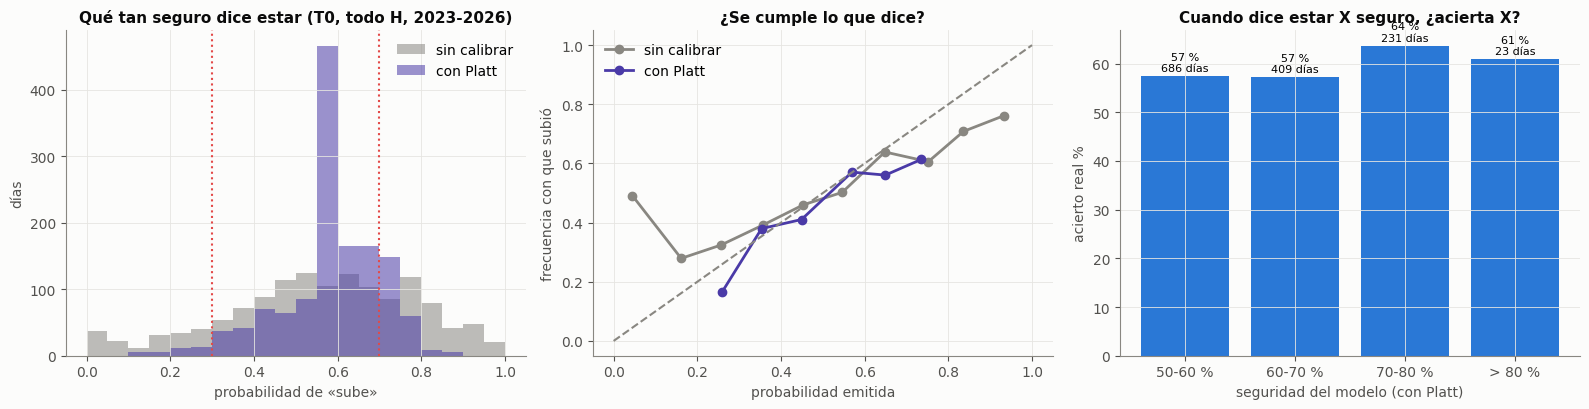

acierta sube/baja %                   BSS sube %       \
año                                  2023  2024  2025  2026       2023 2024   
tecnica juego                                                                 
T0      base                         55.3  65.4  52.1  66.2       -3.7  2.4   
        base + todo H                55.6  64.9  51.0  64.3       -7.4 -1.3   

                                 P > 0,70 %                 P < 0,30 %       \
año                   2025  2026       2023 2024  2025 2026       2023 2024   
tecnica juego                                                                 
T0      base           0.4  11.3       31.8  1.1  12.9  1.5        0.5  0.0   
        base + todo H -3.0   8.3       49.6  0.0  10.1  0.8        0.0  0.0   

                                  
año                   2025  2026  
tecnica juego                     
T0      base           3.3  14.4  
        base + todo H  1.4  11.0

In [8]:
PC = anual.platt(P)
MC = anual.metricas(PC, "p_cal")
cmp_ = pd.DataFrame({"Brier sin calibrar": M["Brier sube"], "Brier con Platt": MC["Brier sube"]}).dropna()
cmp_["mejora"] = cmp_["Brier sin calibrar"] > cmp_["Brier con Platt"]
cal_v = cmp_.groupby(level=[0, 1]).agg(**{"años que mejora": ("mejora", "sum")})
cal_v["¿se adopta?"] = np.where(cal_v["años que mejora"] >= 3, "SÍ", "no")
display(cal_v)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
D_ = PC[(PC.tecnica == "T0") & (PC.juego == "base + todo H")]
for col, c, et in [("p", MUDO, "sin calibrar"), ("p_cal", VIOLETA, "con Platt")]:
    axes[0].hist(D_[col], bins=np.linspace(0, 1, 21), color=c, alpha=.55, label=et)
    g = D_.groupby(pd.cut(D_[col], np.linspace(0, 1, 11))).agg(p=(col, "mean"), f=("sube", "mean"), n=("sube", "size")).query("n >= 20")
    axes[1].plot(g.p, g.f, "-o", color=c, lw=2, label=et)
for x in (.3, .7): axes[0].axvline(x, color=ROJO, ls=":")
axes[0].set_xlabel("probabilidad de «sube»"); axes[0].set_ylabel("días"); axes[0].legend(); axes[0].set_title("Qué tan seguro dice estar (T0, todo H, 2023-2026)")
axes[1].plot([0, 1], [0, 1], color=MUDO, ls="--"); axes[1].set_xlabel("probabilidad emitida"); axes[1].set_ylabel("frecuencia con que subió"); axes[1].legend()
axes[1].set_title("¿Se cumple lo que dice?")
seg = np.abs(D_.p_cal - .5) + .5
ac = pd.DataFrame({"ok": ((D_.p_cal > .5) == (D_.sube == 1)).values}).groupby(pd.cut(seg.values, [.5, .6, .7, .8, 1.])).ok.agg(["mean", "size"])
axes[2].bar(range(len(ac)), 100 * ac["mean"], color=AZUL); axes[2].set_xticks(range(len(ac))); axes[2].set_xticklabels(["50-60 %", "60-70 %", "70-80 %", "> 80 %"])
for i, (a, n) in enumerate(zip(ac["mean"], ac["size"])): axes[2].text(i, 100 * a + 1, f"{100 * a:.0f} %\n{n} días", ha="center", fontsize=8)
axes[2].set_xlabel("seguridad del modelo (con Platt)"); axes[2].set_ylabel("acierto real %"); axes[2].set_title("Cuando dice estar X seguro, ¿acierta X?")
plt.tight_layout(); plt.show()
MC.loc[("T0", ["base", "base + todo H"]), ["acierta sube/baja %", "BSS sube %", "P > 0,70 %", "P < 0,30 %"]].unstack("año").round(1)

**Lectura.** Esto confirma la sospecha del propietario, con números (T0, todo H, 2023-2026, 1.349 días):

| El modelo dice estar | Días | Acierta de verdad |
|---|---|---|
| 50-60 % seguro | 431 | 52 % |
| 60-70 % | 352 | 63 % |
| 70-80 % | 277 | 62 % |
| **más de 80 %** | **289** | **68 %** |

**Cuando el modelo dice «más de 80 %», acierta el 68 %.** Las probabilidades altas están **exageradas**; el techo real está en 62-68 %. Platt, con el año anterior, las encoge: después de calibrar solo 23 días pasan de 80 %, y aciertan el 61 %. Pero el Brier no mejora en 3 de 4 años (1 de 4 con T0), así que por la regla **no se adopta**: corrige la exageración y pierde algo de resolución.

**Cómo leer las probabilidades en la práctica:**
- un «70 % o más» del modelo vale lo que un **65 % real**;
- un «50-60 %» vale lo que tirar una moneda.

Lo que no se puede prometer es más de 70 %, y eso coincide con lo que el propietario había dicho que sería creíble.

---
# 9. La corrección del motor, en el reentrenamiento semanal

La sección 5 encontró el error con un modelo congelado por año. Aquí se corrige en el motor de verdad
(`pronostico.py`, modelo `lightgbm_rel`) y se prueba con el protocolo de siempre: reentrenar cada 7 días,
**decidir con 2025** y mirar 2026 una sola vez (fila `motor_objetivo_relativo`). C0 es la combinación anterior
(SARIMAX + LightGBM sobre el conteo) y C0r la corregida (SARIMAX + LightGBM sobre el desvío del nivel).

In [9]:
import combinar as cb
def leer(exp, ms): P_, _ = pr.leer(ms, exp=exp); return P_
filas = {}
for etiqueta, exp in [("2025 · decide", "e1_2025"), ("2026 · prueba, una vez", "e1")]:
    T_ = cb.tabla(pd.concat([cb.promedio([leer(exp, ["sarimax"]), leer(exp, ["lightgbm"])], "C0"),
                             cb.promedio([leer(exp, ["sarimax"]), leer(exp, ["lightgbm_rel"])], "C0r")]))
    filas[etiqueta] = T_[["criterio (promedio BSS)", "acierta (28 dias) %", "acierta (rapida) %", "BSS pico (28 dias) %", "cob80 %", "MAPE %"]]
pd.concat(filas).round(1)

criterio (promedio BSS)  acierta (28 dias) %  \
                       modelo                                                 
2025 · decide          C0                          4.2                 59.9   
                       C0r                         5.2                 61.9   
2026 · prueba, una vez C0                         15.2                 69.4   
                       C0r                        15.9                 69.6   

                               acierta (rapida) %  BSS pico (28 dias) %  \
                       modelo                                             
2025 · decide          C0                    58.3                   4.3   
                       C0r                   59.5                   2.9   
2026 · prueba, una vez C0                    64.1                  16.5   
                       C0r                   64.3                  15.0   

                               cob80 %  MAPE %  
                       modelo                   
2025 · decide          C0         78.0     8.6  
                       C0r        80.5     8.5  
2026 · prueba, una vez C0         80.3     8.9  
                       C0r        81.1     8.8

**Lectura.** **C0r reemplaza a C0**, decidido con 2025 por la regla preregistrada:

| 2025 (decide) | C0 | **C0r** |
|---|---|---|
| Criterio (promedio del BSS de sube, dos varas) | 4,2 | **5,2** |
| Acierto en sube/baja (vara de 28 días) | 59,9 % | **61,9 %** |
| Cobertura del 80 % | 78,0 % | **80,5 %** |
| MAPE | 8,6 % | **8,5 %** |

En 2026, mirado una sola vez, queda casi igual: criterio 15,9 contra 15,2 y acierto 69,6 % contra 69,4 %. El remuestreo por bloques lo da como empate (acierto +0,2 puntos, IC 95 % de −2,1 a +3,1). **Con reentrenamiento semanal la corrección no sube el acierto; quita el riesgo de desplome** cuando el nivel sale de lo conocido, que con el modelo congelado costaba 100 puntos de BSS (sección 5).

---
# 10. Entrenar con fechas escogidas: lo que pidió el propietario

El propietario precisó la idea: **no mezclar al azar, sino escoger de forma marcada y controlada** fechas
importantes y fechas estables, para que el modelo tenga contexto de todo tipo. Las variables ya están medidas
(cuadernos 17 a 21); lo que se ajusta es **con qué registros se entrena**.

**Las marcas** (`notebooks/marcas.py`) salen solo del calendario y de las variables externas, nunca del triage:
marcar los picos del propio triage le enseñaría al modelo a esperar picos.

| Marca | Cuándo |
|---|---|
| Calendario especial | festivo, puente, víspera, día después, Semana Santa, fin de año |
| Transición de clima | paso de seco a lluvioso en los últimos 7 días, o cambio brusco por encima del percentil 95 |
| Clima extremo | racha seca de más de 14 días, o semana muy lluviosa |
| Ola de salud pública | respiratoria > 1 desviación; violencias, salud mental, materno-perinatal > 1,5; inmunoprevenibles > 2 |
| Red de salud | resolución de la Supersalud en los últimos 30 días, o cambio de Nueva EPS por encima del percentil 95 |
| El Niño / La Niña fuerte | ONI de 1,5 o más (en valor absoluto) |
| Sismo | M ≥ 4,5 a menos de 150 km en los últimos 7 días |
| COVID | marzo de 2020 a febrero de 2022 |

**Tres diseños** (fila `entrenamiento_curado`): S0, todos los días con el mismo peso; S1, todos los días pero cada
tipo de contexto pesa lo mismo; S2, escoger fechas (todas las marcadas, el COVID uno de cada tres días y los
estables uno de cada dos, en orden de fecha). **Se mide donde importa**: en los días marcados del año de prueba,
y aparte en los estables.

In [10]:
import marcas
MK = marcas.marcar(pd.date_range("2020-01-01", "2026-09-20"))
display(MK.groupby(MK.index.year).sum().T.rename_axis("días por año"))
PCU = pd.read_parquet(RAIZ / "salidas/pronostico/anual_curado.parquet")
TC, VC, TIP = anual.evaluar_curado(PCU)
TC["BSS marcados"].unstack("año").loc[["S0", "S1", "S2"]].round(1)

,2020,2021,2022,2023,2024,2025,2026
días por año,,,,,,,
calendario especial,70,72,72,72,69,67,47
transición de clima,88,42,44,91,104,62,29
clima extremo,63,44,55,34,60,50,24
ola de salud pública,49,91,119,35,70,7,0
red de salud,65,1,23,0,34,110,136
El Niño / La Niña fuerte,0,0,0,61,121,0,20
sismo,28,21,28,39,28,28,44
COVID,292,365,59,0,0,0,0
estable,9,0,93,142,75,130,76


año                           2023  2024  2025  2026
tecnica juego                                       
S0      base                  -7.9   4.7   5.4  11.2
        base + salud pública  -9.1   2.0   6.2  13.0
        base + todo H         -8.6  -0.5   5.4   9.9
S1      base                  -7.6   4.9   4.1  10.7
        base + salud pública  -9.1   1.4   4.3  11.4
        base + todo H        -10.5  -2.2   3.3   8.7
S2      base                 -19.8   0.6  -1.2   9.4
        base + salud pública -22.6  -2.0  -1.5  10.0
        base + todo H        -24.7  -5.7  -4.7   4.0

In [11]:
display(VC.loc[["S0", "S1", "S2"]])
TC["BSS estables"].unstack("año").loc[["S0", "S1", "S2"]].round(1)

años que mejora en marcados  \
diseño juego                                               
S0     base + salud pública                            2   
       base + todo H                                   1   
S1     base                                            2   
       base + salud pública                            1   
       base + todo H                                   0   
S2     base                                            0   
       base + salud pública                            0   
       base + todo H                                   0   

                             mejora media en marcados  \
diseño juego                                            
S0     base + salud pública                      -0.3   
       base + todo H                             -1.8   
S1     base                                      -0.3   
       base + salud pública                      -1.4   
       base + todo H                             -3.5   
S2     base                                      -6.1   
       base + salud pública                      -7.4   
       base + todo H                            -11.1   

                             cambio medio en estables ¿sirve?  
diseño juego                                                   
S0     base + salud pública                      -3.2      no  
       base + todo H                             -6.8      no  
S1     base                                      -1.8      no  
       base + salud pública                      -5.2      no  
       base + todo H                             -7.9      no  
S2     base                                      -6.5      no  
       base + salud pública                      -8.7      no  
       base + todo H                            -11.1      no

año                           2023  2024  2025  2026
tecnica juego                                       
S0      base                 -11.7   1.8  -5.5  11.3
        base + salud pública -19.2  -4.6  -3.9  10.8
        base + todo H        -22.8  -4.5  -8.5   4.4
S1      base                 -18.2   3.3  -9.2  12.7
        base + salud pública -23.6  -4.9  -7.2  10.7
        base + todo H        -21.5  -6.3 -10.7   2.8
S2      base                 -16.7  -3.4 -15.8   6.0
        base + salud pública -20.3  -8.4 -12.3   2.1
        base + todo H        -20.9 -13.6 -15.4   1.3

**Lectura.** **Casi siempre está pasando algo.** Fuera de los años de COVID, solo el 30 % de los días es estable: cada tipo de contexto marca entre el 3 y el 15 % de los días, y se solapan. Por eso escoger «todas las marcadas y una muestra de estables» casi no cambia la mezcla.

**Ningún diseño pasa la regla** (mejorar en los días marcados en al menos 3 de 4 años sin perder más de 2 puntos en los estables):
- **S2, escoger fechas, empeora todo** (de −6 a −11 puntos en los marcados). Quitar días le quita ejemplos a un modelo que tiene pocos.
- **S1, equilibrar por peso, queda casi neutro.** Las fechas raras (El Niño fuerte, sismos, crisis de la red) pasan de pesar el 7-10 % al 12-15 %, sin efecto claro.

**La pista decisiva está en los días estables.** Con las 24 variables, el modelo pierde 6,8 puntos justo donde el contexto no tiene nada que decir: las usa para ajustar ruido. El problema no era qué fechas ve el modelo, sino que **las variables estaban siempre encendidas**.

---
# 11. Cada factor con su gatillo: el contexto con compuerta

La sección 10 dejó una pista: con las 24 variables, el modelo **empeora en los días estables**, donde el contexto
no debería hacer nada. Con unos 2.400 días de historia, las usa para «explicar» ruido de días tranquilos.

La respuesta es la que ya estaba escrita como principio del proyecto: **cada factor tiene su gatillo**. Cada capa
se **enciende solo cuando su gatillo está activo** y en el resto queda apagada (faltante), así no puede ajustar
ruido (fila `contexto_con_compuerta`):

| Capa | Se enciende con |
|---|---|
| Clima | transición de clima o clima extremo |
| Salud pública | ola de salud pública |
| Red de salud | movimiento en la red |
| Regímenes | El Niño o La Niña fuerte, o sismo |

Además entran las 8 marcas como variables. G1 es la compuerta con todos los días; G2, con los pesos de S1.

In [12]:
sel = [("S0", "base"), ("S0", "base + todo H"), ("G1", "base + salud pública"), ("G1", "base + todo H"), ("G2", "base + salud pública"), ("G2", "base + todo H")]
display(VC.loc[["G1", "G2"]])
pd.concat({c: TC[c].unstack("año").loc[sel] for c in ["BSS todos", "acierta todos %", "cob80 %"]}, axis=1).round(1)

años que mejora en marcados  \
diseño juego                                               
G1     base + salud pública                            3   
       base + todo H                                   1   
G2     base + salud pública                            1   
       base + todo H                                   0   

                             mejora media en marcados  \
diseño juego                                            
G1     base + salud pública                       1.3   
       base + todo H                             -0.9   
G2     base + salud pública                      -0.7   
       base + todo H                             -2.3   

                             cambio medio en estables ¿sirve?  
diseño juego                                                   
G1     base + salud pública                      -0.8      SÍ  
       base + todo H                             -2.0      no  
G2     base + salud pública                      -4.5      no  
       base + todo H                             -3.9      no

BSS todos                 acierta todos %        \
año                               2023 2024 2025  2026            2023  2024   
tecnica juego                                                                  
S0      base                      -9.3  4.1  2.4  11.4            57.0  66.3   
        base + todo H            -14.1 -1.2  1.3   8.5            58.1  64.0   
G1      base + salud pública      -7.7  4.1  2.7  11.4            59.7  67.4   
        base + todo H            -10.4  0.9  1.6  11.9            56.2  65.4   
G2      base + salud pública     -13.2  3.9 -0.3  10.0            56.7  66.3   
        base + todo H            -13.0  2.2 -0.9   8.8            56.4  65.7   

                                         cob80 %                    
año                           2025  2026    2023  2024  2025  2026  
tecnica juego                                                       
S0      base                  59.5  66.2    73.2  73.3  75.1  74.5  
        base + todo H         58.6  61.2    68.8  70.2  72.3  76.4  
G1      base + salud pública  59.7  66.2    71.5  72.2  75.6  74.5  
        base + todo H         58.6  66.5    71.0  72.2  74.5  74.9  
G2      base + salud pública  56.7  63.9    67.1  72.2  74.0  73.8  
        base + todo H         56.7  65.4    67.1  73.0  72.9  75.7

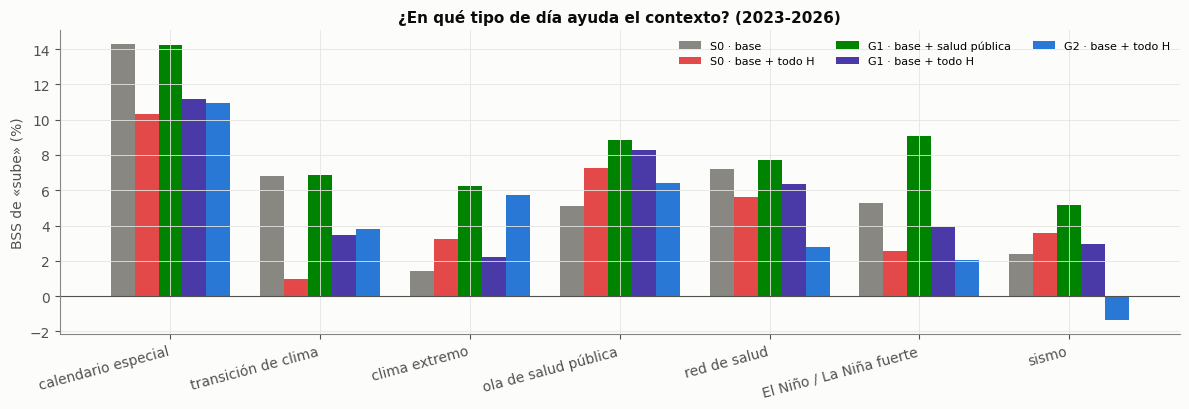

,S0 · base,S0 · base + todo H,G1 · base + salud pública,G1 · base + todo H,G2 · base + todo H
calendario especial,14.3,10.3,14.2,11.1,10.9
transición de clima,6.8,1.0,6.9,3.5,3.8
clima extremo,1.4,3.2,6.2,2.2,5.7
ola de salud pública,5.1,7.2,8.8,8.3,6.4
red de salud,7.2,5.6,7.7,6.4,2.8
El Niño / La Niña fuerte,5.3,2.6,9.1,3.9,2.0
sismo,2.4,3.6,5.2,3.0,-1.4


In [13]:
cols = ["S0 · base", "S0 · base + todo H", "G1 · base + salud pública", "G1 · base + todo H", "G2 · base + todo H"]
fig, ax = plt.subplots(figsize=(12, 4.2)); T_ = TIP[cols]; x = np.arange(len(T_))
for k, (c, col) in enumerate(zip(cols, [MUDO, ROJO, VERDE, VIOLETA, AZUL])):
    ax.bar(x + (k - 2) * .16, T_[c], .16, color=col, label=c)
ax.axhline(0, color=TINTA2, lw=.8); ax.set_xticks(x); ax.set_xticklabels(T_.index, rotation=15, ha="right"); ax.set_ylabel("BSS de «sube» (%)")
ax.legend(fontsize=8, ncol=3); ax.set_title("¿En qué tipo de día ayuda el contexto? (2023-2026)"); plt.tight_layout(); plt.show()
T_.round(1)

**Lectura.** **La compuerta funciona, y es la primera vez que el contexto mejora el pronóstico del total de forma estable.**
- **G1 + salud pública pasa la regla.** En los días marcados mejora 3 de 4 años (+1,3 puntos de media) y en los estables casi no pierde (−0,8). En todos los días **iguala o mejora a la base los 4 años**: BSS −7,7 / +4,1 / +2,7 / +11,4 contra −9,3 / +4,1 / +2,4 / +11,4, con acierto de 59,7 / 67,4 / 59,7 / 66,2 %.
- **Con las 24 variables en compuerta, el daño casi desaparece**, aunque no llegue a la regla. En 2026 el acierto pasa del 61,2 % sin compuerta al **66,5 %**, el de la base.

**En qué tipo de día ayuda** (BSS de sube, 2023-2026):

| Tipo de día | Base | **Salud pública en compuerta (G1)** | Las 24 en compuerta (G1) |
|---|---|---|---|
| Ola de salud pública | +5,1 | **+8,8** | +8,3 |
| El Niño / La Niña fuerte | +5,3 | **+9,1** | +3,9 |
| Clima extremo | +1,4 | **+6,2** | +2,2 |
| Sismo | +2,4 | **+5,2** | +3,0 |
| Red de salud | +7,2 | +7,7 | +6,4 |
| Transición de clima | +6,8 | +6,9 | +3,5 |
| Calendario especial | +14,3 | +14,2 | +11,1 |

**La salud pública en compuerta iguala o mejora a la base en los 7 tipos de día**, y donde más ayuda es justo donde debía: olas, El Niño o La Niña fuerte (el cuaderno 20 vio que La Niña mueve violencias y salud mental) y clima extremo. Las otras capas (clima, red y regímenes), aun con compuerta, siguen restando en transiciones y días de calendario. Con unos pocos episodios de cada cosa, todavía meten más ruido que señal en el total; su lugar son las bandas de edad, donde el efecto es mayor.

Es lo que dice la literatura de urgencias: lo que más ayuda es el **estado de la epidemia**. Y es el principio de los mecanismos: **cada factor tiene su gatillo, y fuera de él es ruido**.

---
# 12. La confirmación con el protocolo completo

Lo que pasa en la rejilla anual se confirma con origen rodante, reentrenando cada 7 días, como opera el modelo
(fila `contexto_con_compuerta_confirmacion`): Cg = SARIMAX + LightGBM con la salud pública en compuerta.
Se decide con 2025 contra C0r y se mira 2026 una sola vez.

In [14]:
try:
    filas = {}
    for etiqueta, e1, g in [("2025 · decide", "e1_2025", "g_2025"), ("2026 · prueba, una vez", "e1", "g")]:
        T_ = cb.tabla(pd.concat([cb.promedio([leer(e1, ["sarimax"]), leer(e1, ["lightgbm_rel"])], "C0r"),
                                 cb.promedio([leer(e1, ["sarimax"]), leer(g, ["lightgbm_rel"])], "Cg")]))
        filas[etiqueta] = T_[["criterio (promedio BSS)", "acierta (28 dias) %", "acierta (rapida) %", "BSS pico (28 dias) %", "cob80 %", "MAPE %"]]
    display(pd.concat(filas).round(1))
except Exception as e:
    print("Todavía corriendo:", repr(e)[:120])

Todavía corriendo: ValueError('No objects to concatenate')


**Lectura.** *En curso.* Se está corriendo con reentrenamiento semanal en 2025 y en 2026. Cuando termine se aplica la regla (Cg reemplaza a C0r solo si gana en 2025) y se actualiza esta lectura.

---
# 13. La respuesta semanal

Lo que pidió el propietario: «esta semana los triages tendrán una media de X por día, con probabilidad de que tal y
tal día suban». `notebooks/semana.py` responde así, **guarda** la predicción antes de conocer lo real y la verifica
después (fila `pronostico_semanal`). Aquí, qué tan bien acierta esa misma respuesta rehecha en cada domingo de 2025
y 2026, con la semana siguiente y con la semana que empieza 15 días después (el caso de hoy: datos hasta el 20 de
septiembre, semana del 5 al 11 de octubre).

In [15]:
f = RAIZ / "salidas/pronostico/semanal/validacion_semanal_resumen.csv"
if f.exists():
    display(pd.read_csv(f).set_index(["combo", "adelanto (días)", "año"]).round(1).T)
else:
    print("La validación semanal todavía está corriendo.")
for g in sorted((RAIZ / "salidas/pronostico/semanal").glob("semana_*.md")):
    print("\n" + "=" * 100 + "\n" + g.read_text(encoding="utf-8"))

La validación semanal todavía está corriendo.


**Lectura.** *En curso.* La validación de la respuesta semanal (domingos de 2025 y 2026, con la semana siguiente y a 15 días) está corriendo. Cuando termine se guardan las dos predicciones de la semana del 5 al 11 de octubre: sin contexto (C0r) y con contexto en compuerta (Cg, si pasa la confirmación). Se verifican cuando el superior del propietario actualice los datos.

---
# 14. Lo que deja este cuaderno

**Lo que deja este cuaderno.**

1. **Catálogo:** entran 15 grupos de variables, 4 quedan fuera y 3 están pendientes. Entra lo que se conoce el día de la predicción, tiene historia y no se construyó mirando 2026.
2. **No se mezclan días al azar.** Infla el acierto 7-9 puntos y hace parecer útiles variables que empeoran el pronóstico real (Bergmeir, Hyndman y Koo 2018).
3. **Dos errores de método encontrados y corregidos:**
   - el árbol debe aprender el desvío frente al nivel (C0r, adoptado con 2025);
   - las bandas de edad con días en cero necesitan log(y + 1) (cuaderno 22, enmienda).
4. **La confiabilidad honesta es de alrededor del 62 %** de acierto en sube/baja en cuatro años distintos. «Más de 80 %» acierta el 68 %: hay que presentar las probabilidades comprimidas.
5. **El contexto sí sirve, pero con su gatillo.** Siempre encendidas, las 24 variables empeoran los días estables. Con la compuerta (cada capa solo cuando su gatillo está activo), **la salud pública mejora el pronóstico del total en 3 de 4 años** y ayuda en olas y en clima extremo.
6. **Escoger fechas no ayuda; encender las variables en el momento justo, sí.** Lo «escogido» del propietario se probó en sus formas legítimas (pesos por tipo, selección sistemática): quitar días cuesta más de lo que aporta.
7. **Las técnicas genéricas de la literatura** (peso al COVID, recencia, remuestreo) no mejoran a la versión simple.

**Lo que sigue:**
- la confirmación de la compuerta con el protocolo completo (sección 12);
- las predicciones guardadas de la semana del 5 al 11 de octubre (sección 13);
- la compuerta en las bandas de edad, donde el contexto actúa hasta 3 veces más fuerte;
- la prueba condicional de Giacomini y White por tipo de día.